In [21]:
import os
import zipfile
import shutil
from pathlib import Path

# Mount Drive if not already mounted
from google.colab import drive
drive.mount('/content/drive')

DRIVE_RAW_DIR = Path("/content/drive/MyDrive/eldersafe/data/raw")
LOCAL_EXTRACT_BASE = Path("/content/local_raw")

# Updated dictionary to use 'fallen.zip'
dataset_zips = {
    "standing": DRIVE_RAW_DIR / "standing.zip",
    "sitting": DRIVE_RAW_DIR / "sitting.zip",
    "lying_in_bed": DRIVE_RAW_DIR / "lying_in_bed.zip",
    "fallen": DRIVE_RAW_DIR / "fallen.zip"
}

print("Extracting datasets to local runtime scratch space...")
for name, zip_path in dataset_zips.items():
    if not zip_path.exists():
        print(f"Error: Missing zip file for {name} at {zip_path}")
        continue

    target_dir = LOCAL_EXTRACT_BASE / name
    if target_dir.exists():
        shutil.rmtree(target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

    print(f"Unpacking {zip_path.name}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(target_dir)

print("Extraction loop complete.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting datasets to local runtime scratch space...
Unpacking standing.zip...
Unpacking sitting.zip...
Unpacking lying_in_bed.zip...
Unpacking fallen.zip...
Extraction loop complete.


In [22]:
import os
import pandas as pd
from pathlib import Path

image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Explicit class mapping for ElderSafe AI
class_mapping = {
    "standing": 0,
    "sitting": 1,
    "lying_in_bed": 2,
    "fallen": 3
}

all_records = []

print("Building master catalog from local folders...")
for folder_name, class_idx in class_mapping.items():
    target_folder = LOCAL_EXTRACT_BASE / folder_name
    if not target_folder.exists():
        print(f"Warning: Folder {target_folder} missing.")
        continue

    class_images = [
        p for p in target_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print(f"  Class {class_idx} ({folder_name}): Found {len(class_images)} images.")

    for img_path in class_images:
        all_records.append({
            "raw_filepath": str(img_path),
            "filename": img_path.name,
            "source_dataset": folder_name,
            "label": class_idx
        })

df_raw_master = pd.DataFrame(all_records)
print(f"\nTotal indexed samples across all 4 sources: {len(df_raw_master)}")

Building master catalog from local folders...
  Class 0 (standing): Found 204 images.
  Class 1 (sitting): Found 400 images.
  Class 2 (lying_in_bed): Found 144 images.
  Class 3 (fallen): Found 474 images.

Total indexed samples across all 4 sources: 1222


In [23]:
from sklearn.model_selection import train_test_split

random_seed = 42

# 70% Train, 30% Temporary split
df_train, df_temp = train_test_split(
    df_raw_master,
    test_size=0.30,
    random_state=random_seed,
    stratify=df_raw_master["label"]
)

# Split remaining 30% evenly into Validation and Test (15% each)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=random_seed,
    stratify=df_temp["label"]
)

df_train = df_train.copy()
df_train["split"] = "train"

df_val = df_val.copy()
df_val["split"] = "val"

df_test = df_test.copy()
df_test["split"] = "test"

df_split_master = pd.concat([df_train, df_val, df_test]).reset_index(drop=True)
print("Stratified distribution grouping finished.")
print(pd.crosstab(df_split_master["source_dataset"], df_split_master["split"]))

Stratified distribution grouping finished.
split           test  train  val
source_dataset                  
fallen            72    331   71
lying_in_bed      21    101   22
sitting           60    280   60
standing          31    143   30


In [24]:
from PIL import Image
from pathlib import Path

drive_clean_dir = Path("/content/drive/MyDrive/eldersafe/data/cleaned")
drive_clean_dir.mkdir(parents=True, exist_ok=True)

final_manifest_records = []
error_count = 0

print("Processing images and writing to Google Drive storage...")
for idx, row in df_split_master.iterrows():
    raw_path = row["raw_filepath"]
    src_name = row["source_dataset"]
    split_group = row["split"]
    lbl = row["label"]

    target_filename = f"elder_{src_name}_{split_group}_{idx:05d}.jpg"
    target_destination = drive_clean_dir / target_filename

    try:
        with Image.open(raw_path) as img:
            img_rgb = img.convert("RGB")
            img_resized = img_rgb.resize((224, 224), Image.Resampling.LANCZOS)
            img_resized.save(target_destination, "JPEG")

            final_manifest_records.append({
                "cleaned_filepath": str(target_destination),
                "filename": target_filename,
                "source_dataset": src_name,
                "label": lbl,
                "split": split_group
            })
    except Exception:
        error_count += 1
        continue

df_final_manifest = pd.DataFrame(final_manifest_records)
df_final_manifest.to_csv(drive_clean_dir / "master_manifest.csv", index=False)

print("\nPipeline execution complete.")
print(f"Successfully processed and saved: {len(df_final_manifest)} images")
print(f"Skipped damaged files: {error_count}")

print("\nYour Progress Report Table Data:")
print(pd.crosstab(df_final_manifest["label"], df_final_manifest["split"]))

Processing images and writing to Google Drive storage...

Pipeline execution complete.
Successfully processed and saved: 1222 images
Skipped damaged files: 0

Your Progress Report Table Data:
split  test  train  val
label                  
0        31    143   30
1        60    280   60
2        21    101   22
3        72    331   71


In [25]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class ElderSafeDataset(Dataset):
    def __init__(self, manifest_path, split_name, transform=None):
        # Load the master manifest we generated in the previous step
        df = pd.read_csv(manifest_path)
        # Filter rows to match the specific split (train, val, or test)
        self.data = df[df["split"] == split_name].reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = row["cleaned_filepath"]
        label = int(row["label"])

        # Load the image and ensure it is strictly RGB
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

# Define basic normalization transforms for the ANN baseline
# Resizing to 64x64 to keep the fully connected input size reasonable
base_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

manifest_file = "/content/drive/MyDrive/eldersafe/data/cleaned/master_manifest.csv"

# Instantiate train, validation, and test datasets
train_dataset = ElderSafeDataset(manifest_file, "train", transform=base_transforms)
val_dataset = ElderSafeDataset(manifest_file, "val", transform=base_transforms)
test_dataset = ElderSafeDataset(manifest_file, "test", transform=base_transforms)

# Set up DataLoaders with a standard course batch size of 32
# Shuffle is True only for training to maximize generalization
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"DataLoaders successfully initialized:")
print(f"  Train batches: {len(train_loader)} ({len(train_dataset)} images)")
print(f"  Val batches:   {len(val_loader)} ({len(val_dataset)} images)")
print(f"  Test batches:  {len(test_loader)} ({len(test_dataset)} images)")

DataLoaders successfully initialized:
  Train batches: 27 (855 images)
  Val batches:   6 (183 images)
  Test batches:  6 (184 images)


In [26]:
import torch.nn as nn

class ElderSafeANN(nn.Module):
    def __init__(self, input_dim=3*64*64, num_classes=4):
        super(ElderSafeANN, self).__init__()

        self.pipeline = nn.Sequential(
            # Flatten the 3D image tensor into a 1D vector
            nn.Flatten(),

            # Hidden Layer 1
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3), # Regularization to control overfitting

            # Hidden Layer 2
            nn.Linear(256, 64),
            nn.ReLU(),

            # Output Layer (Returns 4 logits)
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.pipeline(x)

# Initialize model and check device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_ann = ElderSafeANN().to(device)
print(f"ANN Baseline Model loaded onto: {device}")

ANN Baseline Model loaded onto: cpu


In [28]:
import torch.optim as optim
import numpy as np

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_ann.parameters(), lr=0.001)

num_epochs = 20
best_val_loss = float('inf')
checkpoint_path = "/content/drive/MyDrive/eldersafe/models/ann_baseline_best.pt"
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

# Arrays to store history for progress report learning curves
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model_ann.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_ann(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # --- VALIDATION PHASE ---
    model_ann.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_ann(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    # Record history logs
    history["train_loss"].append(epoch_train_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)

    print(f"Epoch [{epoch+1:02d}/{num_epochs}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

    # Save checkpoint if validation performance improves
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model_ann.state_dict(), checkpoint_path)
        print(f" Validation loss decreased. Saved checkpoint to Drive.")

print("\nTraining completed successfully.")

Epoch [01/20] Train Loss: 0.9100 | Train Acc: 73.33% | Val Loss: 0.9396 | Val Acc: 81.42%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [02/20] Train Loss: 0.5616 | Train Acc: 81.52% | Val Loss: 1.1546 | Val Acc: 80.87%
Epoch [03/20] Train Loss: 0.3942 | Train Acc: 86.43% | Val Loss: 0.8933 | Val Acc: 85.25%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [04/20] Train Loss: 0.3203 | Train Acc: 88.42% | Val Loss: 1.0381 | Val Acc: 79.78%
Epoch [05/20] Train Loss: 0.3219 | Train Acc: 87.84% | Val Loss: 0.8101 | Val Acc: 87.43%
 Validation loss decreased. Saved checkpoint to Drive.
Epoch [06/20] Train Loss: 0.1977 | Train Acc: 93.22% | Val Loss: 0.8235 | Val Acc: 87.98%
Epoch [07/20] Train Loss: 0.1944 | Train Acc: 92.40% | Val Loss: 0.9045 | Val Acc: 85.79%
Epoch [08/20] Train Loss: 0.1879 | Train Acc: 93.45% | Val Loss: 0.8796 | Val Acc: 87.98%
Epoch [09/20] Train Loss: 0.2318 | Train Acc: 91.58% | Val Loss: 0.8586 | Val Acc: 86.89%
Epoch [10/20] Train Loss:

In [29]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Load the absolute best saved model weights from your training run
checkpoint_path = "/content/drive/MyDrive/eldersafe/models/ann_baseline_best.pt"
model_ann.load_state_dict(torch.load(checkpoint_path, map_location=device))
model_ann.eval()

all_preds = []
all_labels = []

# Disable gradient tracking for pure inference evaluation
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_ann(images)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Calculate key performance metrics
test_accuracy = (all_preds == all_labels).sum() / len(all_labels) * 100
macro_f1 = f1_score(all_labels, all_preds, average='macro')

print("--- ANN BASELINE TEST EVALUATION ---")
print(f"Overall Test Accuracy: {test_accuracy:.2f}%")
print(f"Macro F1-Score:        {macro_f1:.4f}\n")

# Print the per-class metrics (Precision, Recall, F1)
class_names = ["Standing", "Sitting", "Lying in Bed", "Fallen"]
print(classification_report(all_labels, all_preds, target_names=class_names))

--- ANN BASELINE TEST EVALUATION ---
Overall Test Accuracy: 90.22%
Macro F1-Score:        0.8828

              precision    recall  f1-score   support

    Standing       0.84      0.87      0.86        31
     Sitting       0.94      0.97      0.95        60
Lying in Bed       0.89      0.76      0.82        21
      Fallen       0.90      0.90      0.90        72

    accuracy                           0.90       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.90      0.90      0.90       184



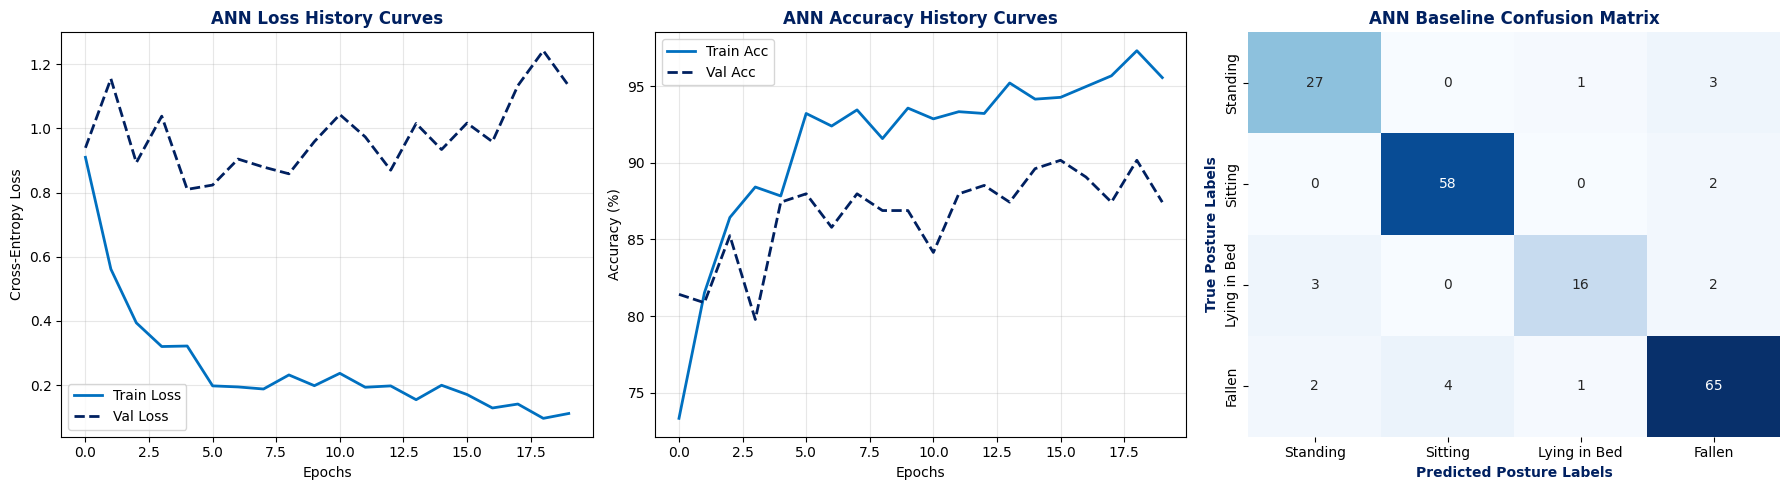

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a clean, professional dual-plot canvas using your blue theme guidelines
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot Loss History Curve
axs[0].plot(history["train_loss"], label="Train Loss", color='#0070C0', lw=2)
axs[0].plot(history["val_loss"], label="Val Loss", color='#002060', lw=2, linestyle='--')
axs[0].set_title("ANN Loss History Curves", weight='bold', color='#002060')
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Cross-Entropy Loss")
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# 2. Plot Accuracy History Curve
axs[1].plot(history["train_acc"], label="Train Acc", color='#0070C0', lw=2)
axs[1].plot(history["val_acc"], label="Val Acc", color='#002060', lw=2, linestyle='--')
axs[1].set_title("ANN Accuracy History Curves", weight='bold', color='#002060')
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy (%)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

# 3. Compute and Plot the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axs[2], cbar=False)
axs[2].set_title("ANN Baseline Confusion Matrix", weight='bold', color='#002060')
axs[2].set_xlabel("Predicted Posture Labels", weight='bold', color='#002060')
axs[2].set_ylabel("True Posture Labels", weight='bold', color='#002060')

plt.tight_layout()
plt.show()

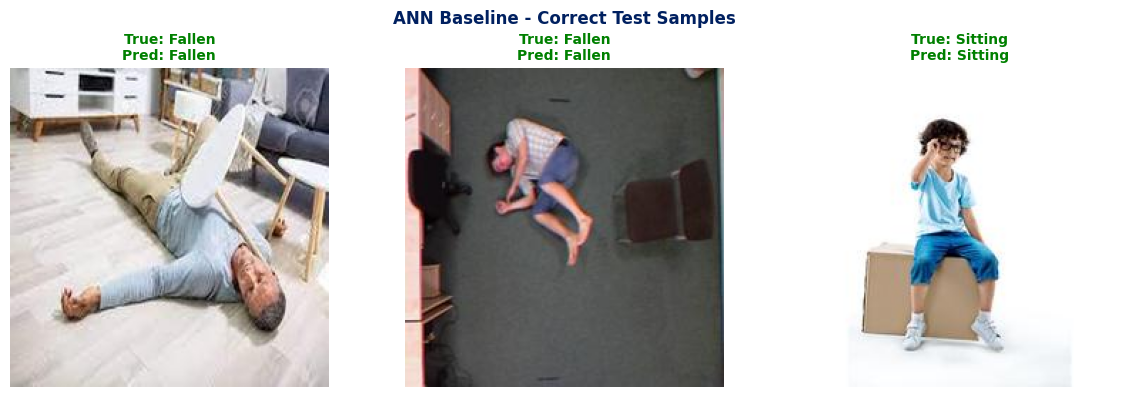

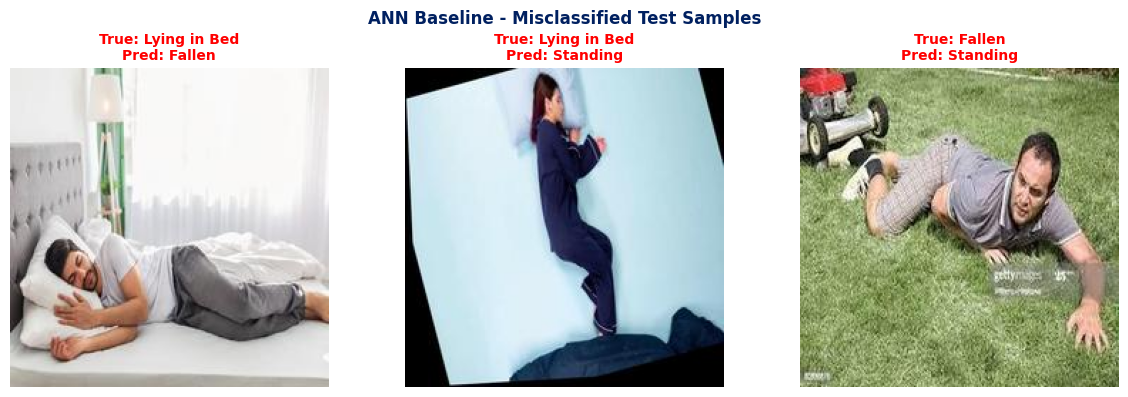

In [31]:
# Create lists to track successful and failed model outcomes
correct_indices = np.where(all_preds == all_labels)[0]
incorrect_indices = np.where(all_preds != all_labels)[0]

def display_samples(indices_list, title_text, max_samples=3):
    plt.figure(figsize=(12, 4))
    samples_to_show = min(max_samples, len(indices_list))

    for i in range(samples_to_show):
        idx = indices_list[i]

        # Access raw image directly from test dataset to avoid dealing with inverse normalization math
        img_path = test_dataset.data.iloc[idx]["cleaned_filepath"]
        img = Image.open(img_path)

        plt.subplot(1, max_samples, i + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}",
                  fontsize=10,
                  color='green' if all_preds[idx] == all_labels[idx] else 'red',
                  weight='bold')
        plt.axis("off")

    plt.suptitle(title_text, fontsize=12, weight='bold', color='#002060')
    plt.tight_layout()
    plt.show()

# Display examples
display_samples(correct_indices, "ANN Baseline - Correct Test Samples")
display_samples(incorrect_indices, "ANN Baseline - Misclassified Test Samples")

In [32]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class ElderSafeDataset(Dataset):
    def __init__(self, manifest_path, split_name, transform=None):
        df = pd.read_csv(manifest_path)
        self.data = df[df["split"] == split_name].reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(row["cleaned_filepath"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

# Standard ImageNet normalization constraints
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

# Training transformations to fight the overfitting seen in your ANN curves
train_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

# Eval transforms (No random alterations allowed here)
eval_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

manifest_file = "/content/drive/MyDrive/eldersafe/data/cleaned/master_manifest.csv"

train_dataset = ElderSafeDataset(manifest_file, "train", transform=train_transforms)
val_dataset = ElderSafeDataset(manifest_file, "val", transform=eval_transforms)
test_dataset = ElderSafeDataset(manifest_file, "test", transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"CNN DataLoaders Ready. Training samples: {len(train_dataset)}")

CNN DataLoaders Ready. Training samples: 855


In [33]:
import torch.nn as nn

class ElderSafeCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(ElderSafeCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1: Input 3x128x128 -> Output 16x64x64
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2: Input 16x64x64 -> Output 32x32x32
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3: Input 32x32x32 -> Output 64x16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 4: Input 64x16x16 -> Output 128x8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Adaptive pooling forces the spatial shape to 1x1 regardless of input size
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4), # Stronger dropout regularizer to beat background memorization
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_cnn = ElderSafeCNN().to(device)

# Compute parameter count for your rubric documentation
total_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print(f"CNN Model loaded onto {device}. Trainable Parameters: {total_params:,}")

CNN Model loaded onto cpu. Trainable Parameters: 106,436


In [35]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_cnn.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 20
best_loss = float('inf')
cnn_save_path = "/content/drive/MyDrive/eldersafe/models/cnn_primary_best.pt"

cnn_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

print("Starting Primary CNN Training Pipeline...")
for epoch in range(num_epochs):
    # Training Loop
    model_cnn.train()
    t_loss, t_correct, t_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_cnn(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        t_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        t_total += labels.size(0)
        t_correct += (preds == labels).sum().item()

    epoch_t_loss = t_loss / t_total
    epoch_t_acc = (t_correct / t_total) * 100

    # Validation Loop
    model_cnn.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model_cnn(imgs)
            loss = criterion(outputs, labels)

            v_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            v_total += labels.size(0)
            v_correct += (preds == labels).sum().item()

    epoch_v_loss = v_loss / v_total
    epoch_v_acc = (v_correct / v_total) * 100

    cnn_history["train_loss"].append(epoch_t_loss)
    cnn_history["train_acc"].append(epoch_t_acc)
    cnn_history["val_loss"].append(epoch_v_loss)
    cnn_history["val_acc"].append(epoch_v_acc)

    print(f"Epoch [{epoch+1:02d}/{num_epochs}] Train Loss: {epoch_t_loss:.4f} Acc: {epoch_t_acc:.2f}% | Val Loss: {epoch_v_loss:.4f} Acc: {epoch_v_acc:.2f}%")

    if epoch_v_loss < best_loss:
        best_loss = epoch_v_loss
        torch.save(model_cnn.state_dict(), cnn_save_path)
        print("Saved new optimal CNN weights to Drive.")

print("\nCNN Training Phase Finalized.")

Starting Primary CNN Training Pipeline...
Epoch [01/20] Train Loss: 0.3376 Acc: 87.13% | Val Loss: 0.5610 Acc: 84.70%
Saved new optimal CNN weights to Drive.
Epoch [02/20] Train Loss: 0.2689 Acc: 90.18% | Val Loss: 0.3622 Acc: 89.62%
Saved new optimal CNN weights to Drive.
Epoch [03/20] Train Loss: 0.3260 Acc: 87.72% | Val Loss: 0.3810 Acc: 85.79%
Epoch [04/20] Train Loss: 0.2828 Acc: 89.59% | Val Loss: 0.4229 Acc: 89.07%
Epoch [05/20] Train Loss: 0.2504 Acc: 90.88% | Val Loss: 0.6579 Acc: 75.96%
Epoch [06/20] Train Loss: 0.2432 Acc: 91.11% | Val Loss: 0.3977 Acc: 87.43%
Epoch [07/20] Train Loss: 0.2387 Acc: 90.88% | Val Loss: 0.4219 Acc: 89.07%
Epoch [08/20] Train Loss: 0.2621 Acc: 89.71% | Val Loss: 0.4162 Acc: 85.25%
Epoch [09/20] Train Loss: 0.3189 Acc: 87.84% | Val Loss: 0.6118 Acc: 79.78%
Epoch [10/20] Train Loss: 0.2729 Acc: 89.36% | Val Loss: 0.3862 Acc: 91.80%
Epoch [11/20] Train Loss: 0.2113 Acc: 93.10% | Val Loss: 0.3920 Acc: 87.43%
Epoch [12/20] Train Loss: 0.2346 Acc: 92.2

In [41]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Load the best weights saved during training
cnn_save_path = "/content/drive/MyDrive/eldersafe/models/cnn_primary_best.pt"
model_cnn.load_state_dict(torch.load(cnn_save_path, map_location=device))
model_cnn.eval()

cnn_preds = []
cnn_labels = []

# No gradients needed for evaluation
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_cnn(images)

        _, predicted = torch.max(outputs, 1)

        cnn_preds.extend(predicted.cpu().numpy())
        cnn_labels.extend(labels.numpy())

cnn_preds = np.array(cnn_preds)
cnn_labels = np.array(cnn_labels)

# Calculate final test metrics
cnn_test_acc = (cnn_preds == cnn_labels).sum() / len(cnn_labels) * 100
cnn_macro_f1 = f1_score(cnn_labels, cnn_preds, average='macro')

print("Primary CNN Model Test Evaluation")
print(f"Overall Test Accuracy: {cnn_test_acc:.2f}%")
print(f"Macro F1-Score:        {cnn_macro_f1:.4f}\n")

class_names = ["Standing", "Sitting", "Lying in Bed", "Fallen"]
print(classification_report(cnn_labels, cnn_preds, target_names=class_names))

Primary CNN Model Test Evaluation
Overall Test Accuracy: 92.93%
Macro F1-Score:        0.9249

              precision    recall  f1-score   support

    Standing       0.97      0.90      0.93        31
     Sitting       0.88      1.00      0.94        60
Lying in Bed       0.95      0.86      0.90        21
      Fallen       0.96      0.90      0.93        72

    accuracy                           0.93       184
   macro avg       0.94      0.92      0.92       184
weighted avg       0.93      0.93      0.93       184



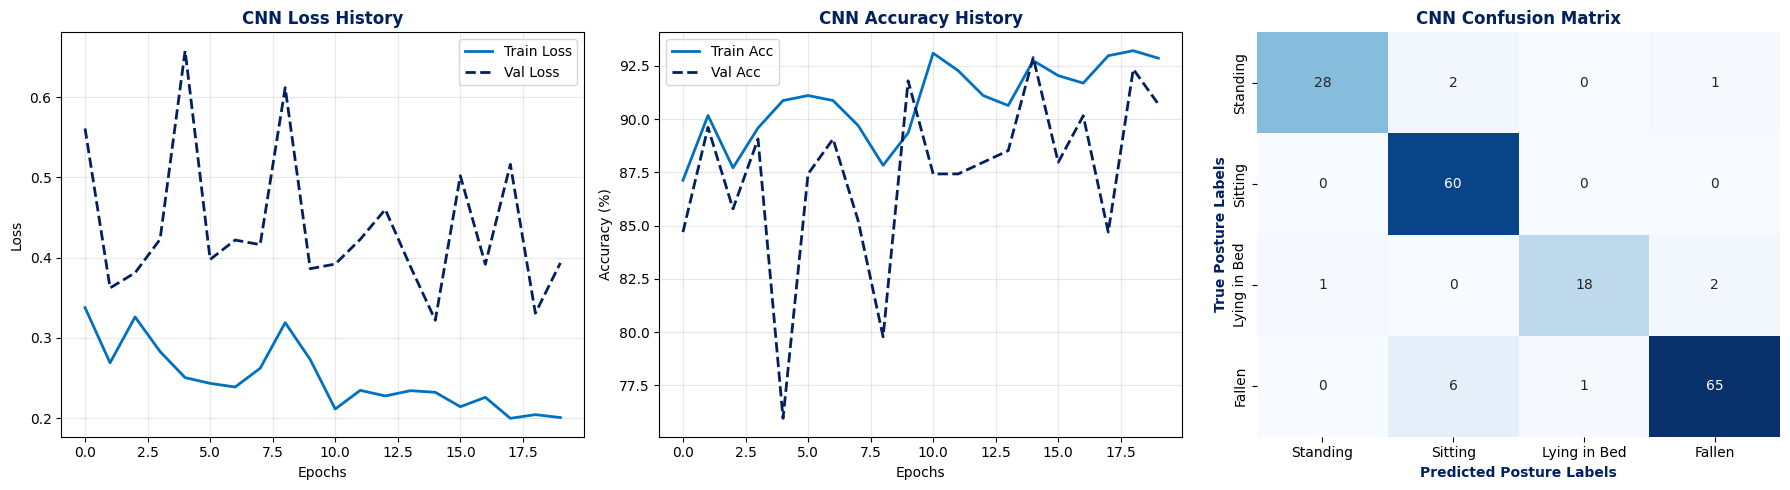

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1. CNN Loss Curve
axs[0].plot(cnn_history["train_loss"], label="Train Loss", color='#0070C0', lw=2)
axs[0].plot(cnn_history["val_loss"], label="Val Loss", color='#002060', lw=2, linestyle='--')
axs[0].set_title("CNN Loss History", weight='bold', color='#002060')
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# 2. CNN Accuracy Curve
axs[1].plot(cnn_history["train_acc"], label="Train Acc", color='#0070C0', lw=2)
axs[1].plot(cnn_history["val_acc"], label="Val Acc", color='#002060', lw=2, linestyle='--')
axs[1].set_title("CNN Accuracy History", weight='bold', color='#002060')
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy (%)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

# 3. CNN Confusion Matrix
cnn_cm = confusion_matrix(cnn_labels, cnn_preds)
sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axs[2], cbar=False)
axs[2].set_title("CNN Confusion Matrix", weight='bold', color='#002060')
axs[2].set_xlabel("Predicted Posture Labels", weight='bold', color='#002060')
axs[2].set_ylabel("True Posture Labels", weight='bold', color='#002060')

plt.tight_layout()
plt.show()

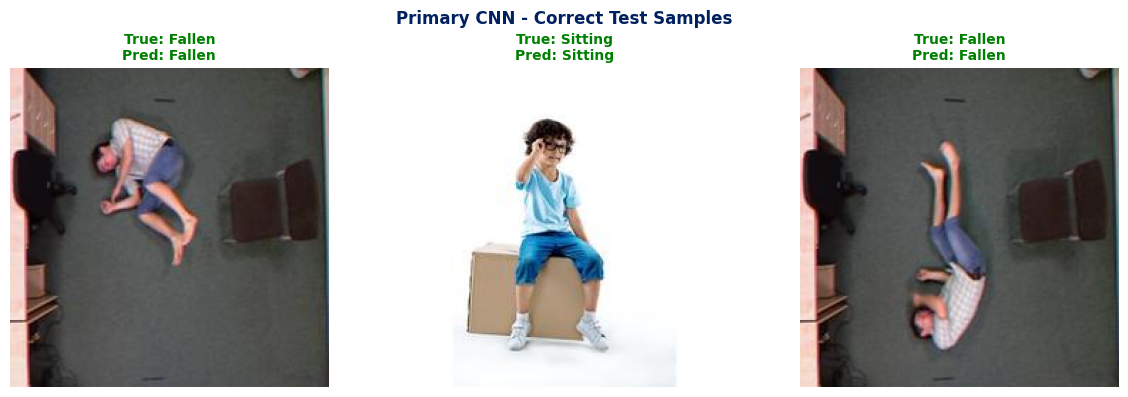

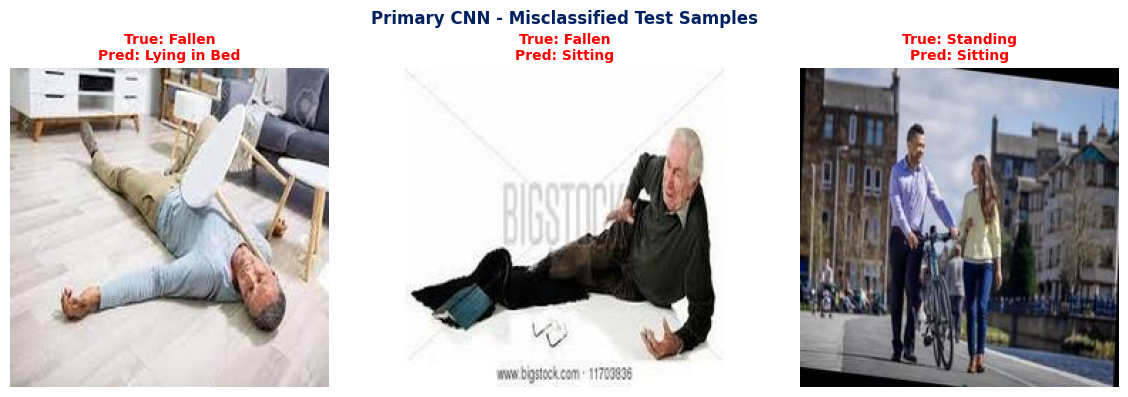

In [43]:
cnn_correct_idx = np.where(cnn_preds == cnn_labels)[0]
cnn_incorrect_idx = np.where(cnn_preds != cnn_labels)[0]

def display_cnn_samples(indices_list, title_text, max_samples=3):
    plt.figure(figsize=(12, 4))
    samples_to_show = min(max_samples, len(indices_list))

    for i in range(samples_to_show):
        idx = indices_list[i]
        img_path = test_dataset.data.iloc[idx]["cleaned_filepath"]
        img = Image.open(img_path)

        plt.subplot(1, max_samples, i + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[cnn_labels[idx]]}\nPred: {class_names[cnn_preds[idx]]}",
                  fontsize=10,
                  color='green' if cnn_preds[idx] == cnn_labels[idx] else 'red',
                  weight='bold')
        plt.axis("off")

    plt.suptitle(title_text, fontsize=12, weight='bold', color='#002060')
    plt.tight_layout()
    plt.show()

# Run the display functions
display_cnn_samples(cnn_correct_idx, "Primary CNN - Correct Test Samples")
display_cnn_samples(cnn_incorrect_idx, "Primary CNN - Misclassified Test Samples")

In [44]:
# Save your raw data grid layout
plt.figure(1) # Select the 3x3 raw preview grid figure
plt.savefig('cleaned_grid.png', bbox_inches='tight', dpi=300)

# Save your ANN evaluation plots
plt.figure(2) # Select the ANN history/confusion matrix figure
plt.savefig('ann_metrics.png', bbox_inches='tight', dpi=300)

# Save your CNN evaluation plots
plt.figure(3) # Select the CNN history/confusion matrix figure
plt.savefig('cnn_metrics.png', bbox_inches='tight', dpi=300)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>